# 02 · Análisis Exploratorio (EDA): univariado y bivariado
## Módulo 3 — Programa Data Science for Business | FUTURA

---

**Entrada:** `01_train`, `01_test` · **Salida:** `reports/eda_decisiones.json` (no transforma datos).

> 🔒 **Todo el EDA se hace sobre TRAIN.** Mirar el test es hacer trampa: cualquier decisión que
> tomes (qué imputar, dónde capear, qué descartar) quedaría contaminada por información que se
> supone que no tienes. Es *leakage a través del analista*, tan real como el del código.

Este notebook **no modifica los datos** — solo los observa y produce un **reporte de decisiones**
que las etapas 03–06 consumirán. Se divide en:
- **Univariado**: cada variable por sí sola (forma, dispersión, normalidad).
- **Bivariado**: cada variable **contra el target** y entre sí, con **tests estadísticos**.
- **Nulos**: patrón y si predicen el target.
- **Vistas por segmento**: cómo cambia todo según el conglomerado del NB01.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pipeline_io import (
    TARGET, SEGMENT_COL, load_stage, save_report, save_table, set_plot_theme,
    diagnostico_univariado, cramers_v, correlation_ratio,
    COLOR_OK, COLOR_BAD, COLOR_NEUTRAL, COLOR_WARN,
)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

set_plot_theme()

train = load_stage("01_train")
target = TARGET

# Separamos metadatos (Segmento, target) de las features
y = train[target]
segmento = train[SEGMENT_COL]
X = train.drop(columns=[target, SEGMENT_COL])

cols_num = X.select_dtypes("number").columns.tolist()
cols_cat = X.select_dtypes(["object", "string"]).columns.tolist()

print("TRAIN:", X.shape)
print("Numéricas :", cols_num)
print("Categóricas:", cols_cat)
print("Tasa de evento:", f"{y.mean():.2%}")

TRAIN: (491, 11)
Numéricas : ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
Categóricas: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']
Tasa de evento: 31.16%


---
# Parte A · Análisis univariado

## 2.1 Ficha descriptiva de cada variable

Empezamos con la "ficha médica": para cada variable, sus estadísticos clave. El
**coeficiente de variación** (CV = std/media) permite comparar dispersión entre variables de
escalas distintas; la **asimetría** (skew) anticipa transformaciones.

In [2]:
ficha = diagnostico_univariado(X)
ficha

,tipo,n,pct_nulos,n_unicos,pct_ceros,media,mediana,std,cv,min,p25,p75,max,asimetria
variable,,,,,,,,,,,,,,
Gender,cat,480,2.24,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Married,cat,488,0.61,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,cat,477,2.85,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,cat,491,0.00,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Self_Employed,cat,463,5.70,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ApplicantIncome,num,491,0.00,417,0.00,5471.454,3846.0,6271.117,1.146,210.0,2878.5,5818.5,81000.0,6.633
CoapplicantIncome,num,491,0.00,242,43.79,1637.149,1250.0,3024.676,1.848,0.0,0.0,2294.5,41667.0,7.942
LoanAmount,num,471,4.07,184,0.00,147.178,128.0,82.972,0.564,9.0,103.5,168.0,650.0,2.400
Loan_Amount_Term,num,480,2.24,10,0.00,342.125,360.0,64.624,0.189,12.0,360.0,360.0,480.0,-2.338


## 2.2 Distribución de las variables numéricas

Para cada numérica: histograma + KDE, y un boxplot para ver la cola. Anotamos **asimetría** y
**curtosis** (colas pesadas).

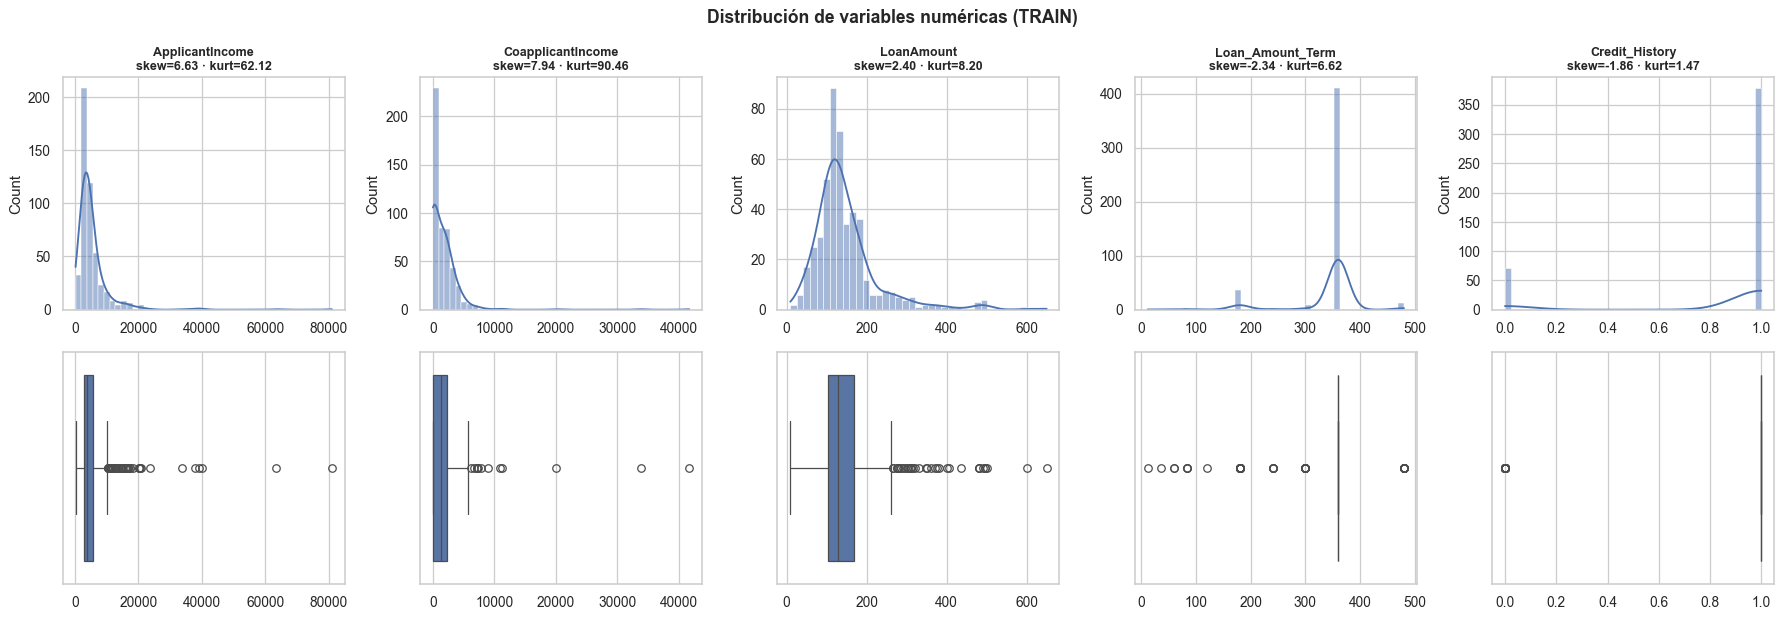

In [3]:
fig, axes = plt.subplots(2, len(cols_num), figsize=(4 * len(cols_num), 7))
for j, c in enumerate(cols_num):
    s = X[c].dropna()
    sns.histplot(s, kde=True, ax=axes[0, j], color=COLOR_NEUTRAL)
    axes[0, j].set_title(f"{c}\nskew={s.skew():.2f} · kurt={s.kurtosis():.2f}", fontsize=10)
    axes[0, j].set_xlabel("")
    sns.boxplot(x=s, ax=axes[1, j], color=COLOR_NEUTRAL)
    axes[1, j].set_xlabel("")
plt.suptitle("Distribución de variables numéricas (TRAIN)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### Test de normalidad

Muchos métodos (Mahalanobis, algunos tests paramétricos) asumen normalidad. La contrastamos con
**Shapiro-Wilk** (H₀: la variable es normal). Un p-valor < 0.05 rechaza la normalidad.

In [4]:
filas_norm = []
for c in cols_num:
    s = X[c].dropna()
    W, p = stats.shapiro(s)
    filas_norm.append({
        "variable": c, "shapiro_W": round(W, 4), "p_valor": f"{p:.2e}",
        "asimetria": round(s.skew(), 3), "curtosis": round(s.kurtosis(), 3),
        "¿normal?": "NO (p<0.05)" if p < 0.05 else "no se rechaza",
    })
print(pd.DataFrame(filas_norm).to_string(index=False))
print()
print(">> Todas rechazan normalidad: colas largas y asimetría. Anticipa el uso del logaritmo (06)")
print("   y una versión ROBUSTA de Mahalanobis en el NB04 (la clásica asume normalidad).")

         variable  shapiro_W  p_valor  asimetria  curtosis    ¿normal?
  ApplicantIncome     0.4667 9.49e-36      6.633    62.116 NO (p<0.05)
CoapplicantIncome     0.4551 4.97e-36      7.942    90.463 NO (p<0.05)
       LoanAmount     0.7903 3.59e-24      2.400     8.204 NO (p<0.05)
 Loan_Amount_Term     0.4780 3.88e-35     -2.338     6.615 NO (p<0.05)
   Credit_History     0.4403 4.29e-35     -1.861     1.470 NO (p<0.05)

>> Todas rechazan normalidad: colas largas y asimetría. Anticipa el uso del logaritmo (06)
   y una versión ROBUSTA de Mahalanobis en el NB04 (la clásica asume normalidad).


## 2.3 Distribución de las variables categóricas

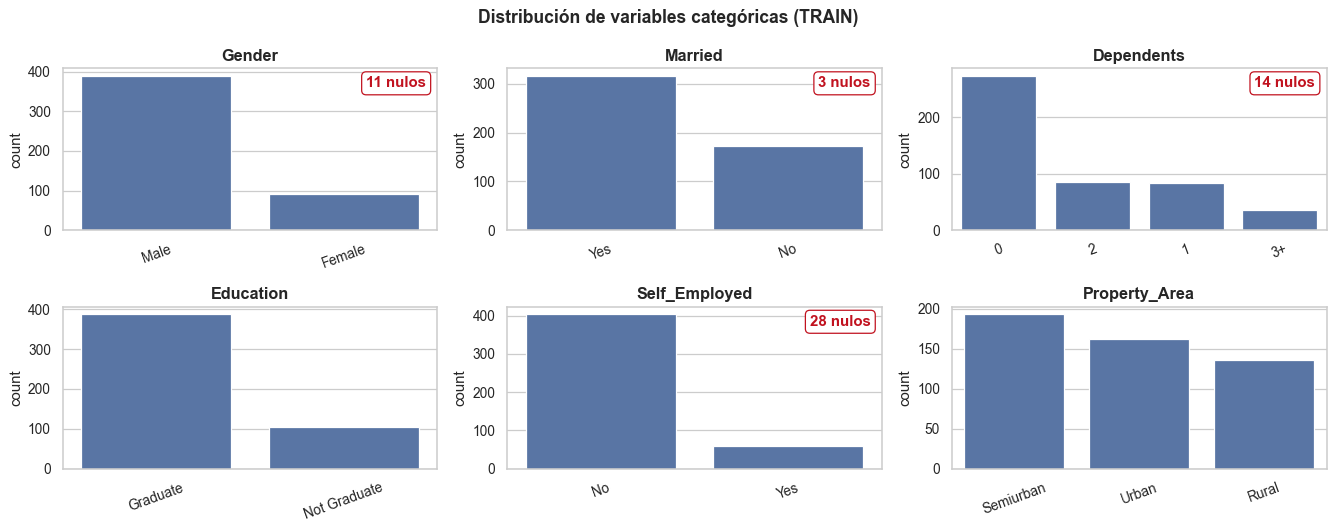

In [5]:
n = len(cols_cat)
fig, axes = plt.subplots((n + 2) // 3, 3, figsize=(15, 3 * ((n + 2) // 3)))
for ax, c in zip(axes.ravel(), cols_cat):
    orden = X[c].value_counts().index
    sns.countplot(data=X, x=c, order=orden, ax=ax, color=COLOR_NEUTRAL)
    ax.set_title(c); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
    nn = X[c].isna().sum()
    if nn:
        ax.text(0.97, 0.95, f"{nn} nulos", transform=ax.transAxes, ha="right", va="top",
                color=COLOR_WARN, fontweight="bold",
                bbox=dict(boxstyle="round", fc="white", ec=COLOR_WARN))
for ax in axes.ravel()[n:]:
    ax.set_visible(False)
plt.suptitle("Distribución de variables categóricas (TRAIN)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

---
# Parte B · Análisis bivariado (contra el target)

Aquí empieza la búsqueda de señal. **La pregunta clave no es cómo se distribuye una variable,
sino cómo cambia la tasa de evento según su valor.** Y no nos conformamos con el gráfico:
acompañamos cada relación con un **test estadístico**.

## 2.4 Numéricas vs target

Comparamos la distribución de cada numérica entre aprobados (0) y rechazados (1). El test
apropiado, dado que **ninguna es normal**, es **Mann-Whitney U** (no paramétrico). Además
medimos la fuerza de la relación con la **correlación biserial-puntual**.

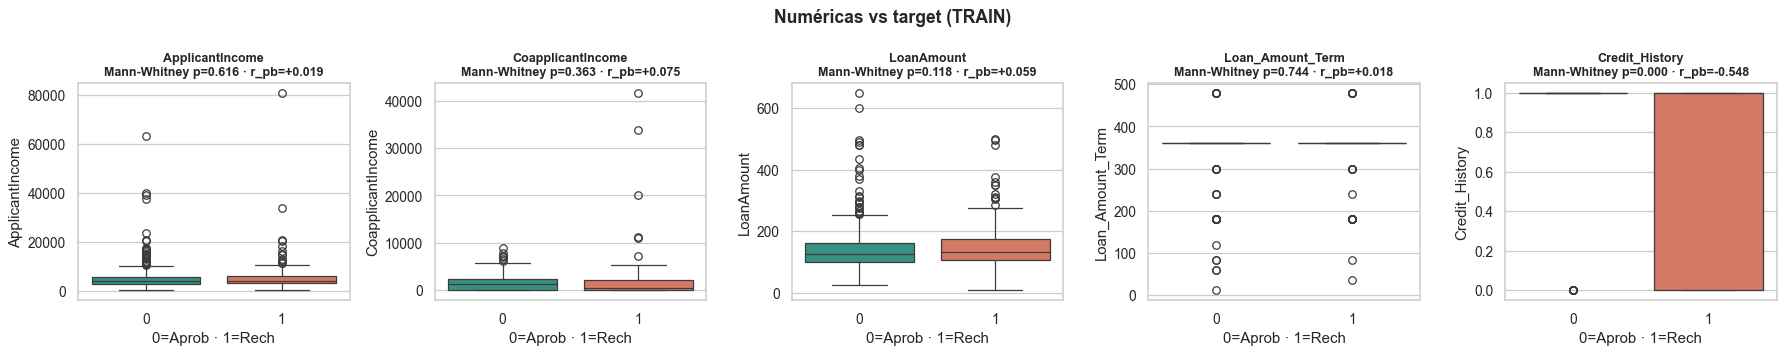

         variable  mannwhitney_p  r_biserial ¿discrimina?
  ApplicantIncome         0.6161      0.0192           no
CoapplicantIncome         0.3625      0.0750           no
       LoanAmount         0.1176      0.0587           no
 Loan_Amount_Term         0.7441      0.0184           no
   Credit_History         0.0000     -0.5483  sí (p<0.05)


In [6]:
fig, axes = plt.subplots(1, len(cols_num), figsize=(4 * len(cols_num), 4))
filas_num_tgt = []
for j, c in enumerate(cols_num):
    sns.boxplot(x=y, y=X[c], ax=axes[j], palette=[COLOR_OK, COLOR_BAD])
    g0 = X.loc[y == 0, c].dropna()
    g1 = X.loc[y == 1, c].dropna()
    U, p = stats.mannwhitneyu(g0, g1)
    # correlación biserial-puntual = Pearson entre la numérica y el target binario
    rpb = stats.pointbiserialr(y[X[c].notna()], X[c].dropna())[0]
    axes[j].set_title(f"{c}\nMann-Whitney p={p:.3f} · r_pb={rpb:+.3f}", fontsize=10)
    axes[j].set_xlabel("0=Aprob · 1=Rech")
    filas_num_tgt.append({"variable": c, "mannwhitney_p": round(p, 4),
                          "r_biserial": round(rpb, 4),
                          "¿discrimina?": "sí (p<0.05)" if p < 0.05 else "no"})
plt.suptitle("Numéricas vs target (TRAIN)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()
print(pd.DataFrame(filas_num_tgt).to_string(index=False))

## 2.5 Categóricas vs target

El gráfico que un analista de riesgo mira primero: **tasa de rechazo por categoría**. Si la
barra es plana, la variable no discrimina. El test es **chi-cuadrado de independencia**, y la
**fuerza** de la asociación se mide con la **V de Cramér** (0 = nula, 1 = total).

In [ ]:
fig, axes = plt.subplots((len(cols_cat) + 2) // 3, 3, figsize=(15, 4 * ((len(cols_cat) + 2) // 3)))
tasa_global = y.mean()
filas_cat_tgt = []
for ax, c in zip(axes.ravel(), cols_cat):
    d = X[[c]].copy(); d[target] = y
    tasa = d.groupby(c, observed=True)[target].agg(["mean", "count"]).sort_values("mean", ascending=False)
    barras = ax.bar([str(i) for i in tasa.index], tasa["mean"], color=COLOR_NEUTRAL)
    ax.axhline(tasa_global, color=COLOR_WARN, ls="--", lw=1.5)
    for b, (m, cnt) in zip(barras, tasa[["mean", "count"]].values):
        ax.text(b.get_x() + b.get_width() / 2, m + 0.012, f"{m:.0%}\nn={int(cnt)}", ha="center", fontsize=8)
    chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(X[c], y))
    v = cramers_v(X[c], y)
    ax.set_title(f"{c}\nchi² p={p:.3f} · Cramér's V={v:.3f}", fontsize=10)
    ax.set_ylabel("tasa rechazo"); ax.tick_params(axis="x", rotation=20)
    ax.set_ylim(0, max(0.75, tasa["mean"].max() * 1.3))
    filas_cat_tgt.append({"variable": c, "chi2_p": round(p, 4), "cramers_v": round(v, 4),
                          "¿asociada?": "sí (p<0.05)" if p < 0.05 else "no"})
for ax in axes.ravel()[len(cols_cat):]:
    ax.set_visible(False)
plt.suptitle("Tasa de evento por categoría (TRAIN)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()
print(pd.DataFrame(filas_cat_tgt).sort_values("cramers_v", ascending=False).to_string(index=False))

## 2.6 Correlación entre numéricas

Pearson (lineal) vs Spearman (monótona). Con variables sesgadas, Spearman suele revelar más.

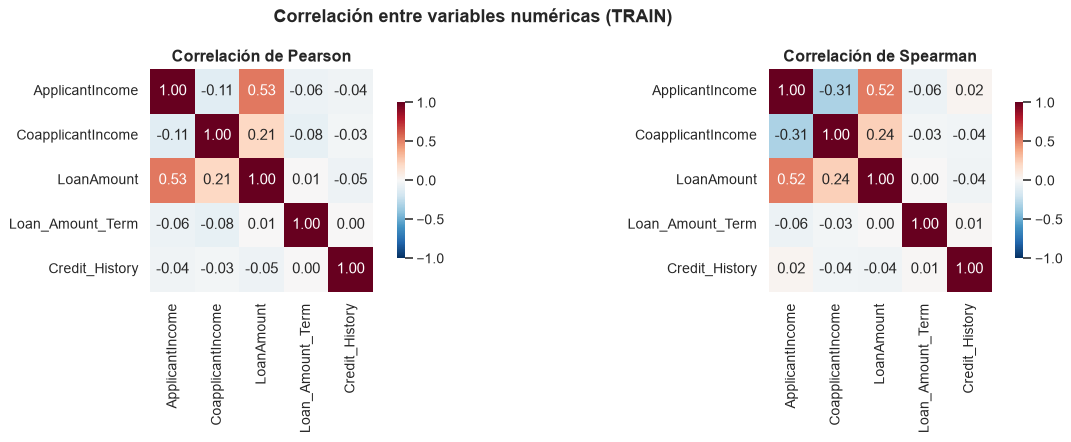

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metodo in zip(axes, ["pearson", "spearman"]):
    corr = X[cols_num].corr(method=metodo)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax,
                vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.7})
    ax.set_title(f"Correlación de {metodo.capitalize()}")
plt.suptitle("Correlación entre variables numéricas (TRAIN)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

---
# Parte C · Análisis de nulos

Antes de imputar (NB06), hay que **entender** los nulos. No es lo mismo un dato que falta al
azar que uno que falta *porque* significa algo.

| Mecanismo | Significado |
|---|---|
| **MCAR** | Falta por azar puro |
| **MAR** | Falta según **otras** variables observadas |
| **MNAR** | Falta según **su propio** valor (no observado) — el peligroso |

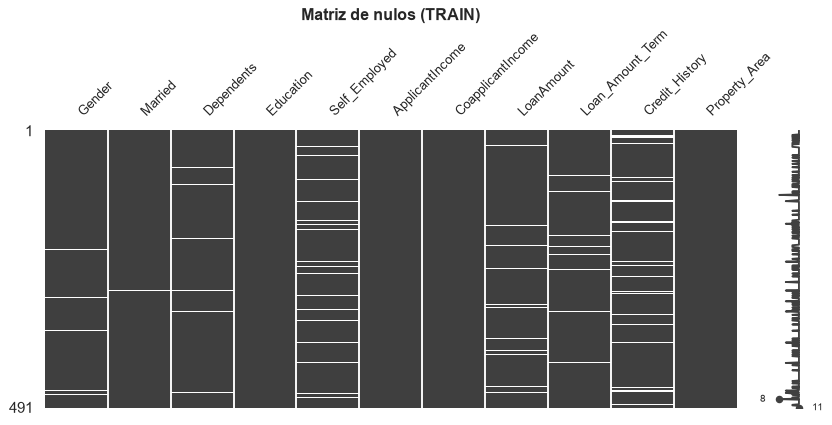

In [ ]:
import missingno as msno
msno.matrix(X, figsize=(11, 4), fontsize=10)
plt.title("Matriz de nulos (TRAIN)", fontsize=13, fontweight="bold")
plt.show()

### ¿Los nulos predicen el target?

Si la tasa de evento cambia según si el dato falta o no, **el nulo tiene información** y borrarlo
o imputarlo silenciosamente destruye señal. Candidato a indicador `_missing` en NB06.

In [ ]:
filas_nulos = []
for c in X.columns[X.isna().any()]:
    marca = X[c].isna()
    dif = (y[marca].mean() - y[~marca].mean()) * 100
    filas_nulos.append({
        "variable": c, "n_nulos": int(marca.sum()), "pct_nulos": f"{marca.mean():.1%}",
        "tasa_SI_nulo": f"{y[marca].mean():.1%}", "tasa_NO_nulo": f"{y[~marca].mean():.1%}",
        "dif_pp": round(dif, 1),
    })
diag_nulos = pd.DataFrame(filas_nulos).sort_values("dif_pp", key=abs, ascending=False)
print(f"Tasa de evento global: {y.mean():.1%}")
print(diag_nulos.to_string(index=False))
print()
print(">> Una diferencia grande en 'dif_pp' = la AUSENCIA del dato es informativa (MNAR).")

Tasa de evento global: 31.2%
        variable  n_nulos pct_nulos tasa_SI_nulo tasa_NO_nulo  dif_pp
         Married        3      0.6%         0.0%        31.4%   -31.4
      LoanAmount       20      4.1%        45.0%        30.6%    14.4
      Dependents       14      2.9%        42.9%        30.8%    12.0
  Credit_History       41      8.4%        24.4%        31.8%    -7.4
          Gender       11      2.2%        36.4%        31.0%     5.3
Loan_Amount_Term       11      2.2%        36.4%        31.0%     5.3
   Self_Employed       28      5.7%        32.1%        31.1%     1.0

>> Una diferencia grande en 'dif_pp' = la AUSENCIA del dato es informativa (MNAR).


---
# Parte D · Vistas por segmento

El EDA global esconde heterogeneidad. Las mismas variables pueden comportarse distinto en cada
conglomerado del NB01. Esto **anticipa la limpieza por segmento del NB03**.

In [ ]:
# Tasa de evento por segmento
tasa_seg = y.groupby(segmento).agg(n="count", tasa="mean")
tasa_seg["tasa"] = (tasa_seg["tasa"] * 100).round(1)
print("Tasa de rechazo por segmento:")
print(tasa_seg.to_string())

Tasa de rechazo por segmento:
            n  tasa
Segmento           
0         219  25.6
1          85  32.9
2         142  38.0
3          45  33.3


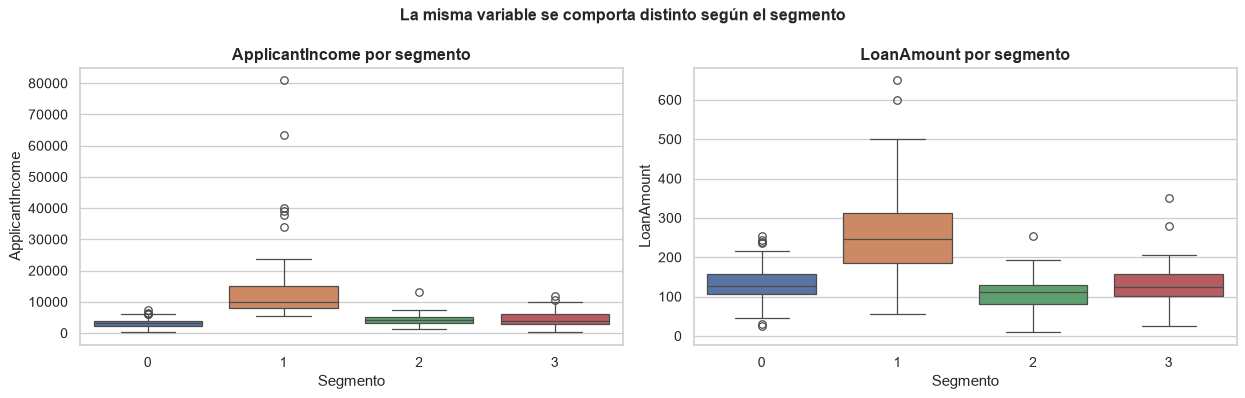

In [ ]:
# Cómo se distribuye una variable clave (ApplicantIncome) por segmento
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
d = X.copy(); d[SEGMENT_COL] = segmento
sns.boxplot(data=d, x=SEGMENT_COL, y="ApplicantIncome", ax=axes[0], palette="deep")
axes[0].set_title("ApplicantIncome por segmento")
sns.boxplot(data=d, x=SEGMENT_COL, y="LoanAmount", ax=axes[1], palette="deep")
axes[1].set_title("LoanAmount por segmento")
plt.suptitle("La misma variable se comporta distinto según el segmento", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

---
## 2.7 Reporte de decisiones del EDA

El EDA no transforma datos, pero **produce decisiones**. Las guardamos en un JSON que las etapas
siguientes leerán, para que la cadena tenga memoria de lo que descubrimos aquí.

In [ ]:
decisiones = {
    "numericas": cols_num,
    "categoricas": cols_cat,
    "tasa_evento_train": float(y.mean()),
    "variables_sesgadas": [c for c in cols_num if abs(X[c].skew()) > 1],
    "candidatas_log": [c for c in cols_num if X[c].skew() > 1],
    "nulos": {c: int(X[c].isna().sum()) for c in X.columns if X[c].isna().any()},
    "nulos_informativos": diag_nulos.loc[diag_nulos["dif_pp"].abs() > 5, "variable"].tolist(),
    "asociacion_target": {
        **{r["variable"]: r["cramers_v"] for r in filas_cat_tgt},
        **{r["variable"]: abs(r["r_biserial"]) for r in filas_num_tgt},
    },
}
save_report(decisiones, "eda_decisiones")

# Tablas analíticas a CSV (abribles en Excel)
save_table(ficha, "eda_ficha_univariada")
tabla_asociacion = (pd.DataFrame(filas_cat_tgt + [{"variable": r["variable"],
                    "chi2_p": None, "cramers_v": abs(r["r_biserial"]),
                    "¿asociada?": r["¿discrimina?"]} for r in filas_num_tgt])
                    .sort_values("cramers_v", ascending=False))
save_table(tabla_asociacion, "eda_asociacion_target")
save_table(diag_nulos, "eda_nulos")
print("Reportes → reports/eda_decisiones.json + eda_*.csv (3 tablas)")

Reportes → reports/eda_decisiones.json + eda_*.csv (3 tablas)


## 🔍 Lectura analítica del EDA

No basta con generar gráficos: hay que **decir qué muestran**. Estos son los hallazgos que
condicionan las etapas siguientes.

In [ ]:
top_asoc = tabla_asociacion.dropna(subset=["cramers_v"]).head(3)
print("LO QUE DICEN LOS DATOS DE ESTA CARTERA")
print("=" * 66)
print("1. SEÑAL — variables más asociadas al rechazo (Cramér's V / |r|):")
for _, r in top_asoc.iterrows():
    print(f"     · {r['variable']:16s} {r['cramers_v']:.3f}")
print("   >> Credit_History domina. Recuerda (NB01 §1.3): ES la regla del comité,")
print("      no una relación descubierta. Lo confirmaremos en cada etapa.")
print()
print("2. FORMA — asimetría fuerte en ingresos y monto:")
for c in decisiones["candidatas_log"]:
    print(f"     · {c:18s} skew={X[c].skew():+.2f}  → candidata a log (NB06)")
print()
print("3. NULOS — patrón y si informan:")
if decisiones["nulos_informativos"]:
    print(f"     · Informativos (dif>5pp): {decisiones['nulos_informativos']}")
    print("       → NO imputar a ciegas: crear indicador _missing (NB06)")
else:
    print("     · Ninguno cambia la tasa de evento >5pp: nulos ~aleatorios, imputables")
print()
print("4. HETEROGENEIDAD — los segmentos tienen tasas de rechazo distintas:")
print(f"     · de {tasa_seg['tasa'].min()}% a {tasa_seg['tasa'].max()}%  → justifica análisis por segmento (NB03)")
print("=" * 66)
print()
print("Siguiente paso → 03_limpieza_dura.ipynb")

LO QUE DICEN LOS DATOS DE ESTA CARTERA
1. SEÑAL — variables más asociadas al rechazo (Cramér's V / |r|):
     · Credit_History   0.548
     · Property_Area    0.160
     · Married          0.076
   >> Credit_History domina. Recuerda (NB01 §1.3): ES la regla del comité,
      no una relación descubierta. Lo confirmaremos en cada etapa.

2. FORMA — asimetría fuerte en ingresos y monto:
     · ApplicantIncome    skew=+6.63  → candidata a log (NB06)
     · CoapplicantIncome  skew=+7.94  → candidata a log (NB06)
     · LoanAmount         skew=+2.40  → candidata a log (NB06)

3. NULOS — patrón y si informan:
     · Informativos (dif>5pp): ['Married', 'LoanAmount', 'Dependents', 'Credit_History', 'Gender', 'Loan_Amount_Term']
       → NO imputar a ciegas: crear indicador _missing (NB06)

4. HETEROGENEIDAD — los segmentos tienen tasas de rechazo distintas:
     · de 25.6% a 38.0%  → justifica análisis por segmento (NB03)

Siguiente paso → 03_limpieza_dura.ipynb
